# 02 — MURA XR_WRIST: Professional Preprocessing


## Frozen preprocessing policy

- Decode each radiograph as grayscale (`L`), then replicate it to 3 RGB channels for ImageNet-pretrained ResNet-18.
- Preserve all anatomy: black-pad to square before bilinear resize to 224×224.
- Apply fixed ImageNet mean/std normalization. No dataset statistics are fit on validation or test data.
- Evaluation is deterministic and has **no augmentation**.
- Fine-tuning-only augmentation is conservative: rotation ±7°, brightness ±8%, contrast ±10%.
- Explicitly excluded: horizontal flips, random crops, CLAHE, per-image min/max normalization, blur, sharpening, and synthetic noise.

For the frozen ResNet baseline, use the deterministic evaluation transform for **both** train and validation feature extraction.

In [ ]:

import io
import json
import hashlib
import platform
import zipfile
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import PIL
import torch
import torchvision
from PIL import Image, ImageOps, UnidentifiedImageError
from torchvision import transforms
from torchvision.transforms import InterpolationMode

In [38]:


NOTEBOOK_VERSION = '1.0.0'
RUNTIME = {
    'notebook_version': NOTEBOOK_VERSION,
    'python': platform.python_version(),
    'torch': torch.__version__,
    'torchvision': torchvision.__version__,
    'pillow': PIL.__version__,
}
RUNTIME

{'notebook_version': '1.0.0',
 'python': '3.13.15',
 'torch': '2.11.0+cu130',
 'torchvision': '0.26.0+cu130',
 'pillow': '11.3.0'}

In [39]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [40]:
# EDIT THESE PATHS ONLY to match your personal Drive layout.
# Do NOT substitute the official MURA valid manifest here.
PROJECT_DIR = Path('/content/drive/MyDrive/DATA')
SPLITS_DIR = PROJECT_DIR / 'WRIST_SPLITS'
RAW_ZIP = PROJECT_DIR / 'MURA-v1.1_files.zip'
OUTPUT_DIR = PROJECT_DIR / 'PREPROCESSED_WRIST'
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
TRAIN_MANIFEST = SPLITS_DIR / 'wrist_internal_train.csv'
VALIDATION_MANIFEST = SPLITS_DIR / 'wrist_internal_val.csv'
for required_path in (RAW_ZIP, TRAIN_MANIFEST, VALIDATION_MANIFEST):
    assert required_path.exists(), f'Not found: {required_path}'
print('Input ZIP:', RAW_ZIP)
print('Output metadata folder:', OUTPUT_DIR)

Input ZIP: /content/drive/MyDrive/DATA/MURA-v1.1_files.zip
Output metadata folder: /content/drive/MyDrive/DATA/PREPROCESSED_WRIST


In [ ]:
# OVERWRITE PROTECTION (added 17.10.2026, after the run recorded in this notebook).
# PREPROCESSED_WRIST is a shared team folder: Notebooks 03, 05 and 07 read its manifests.
# If any output of this notebook already exists there, this run writes to a NEW folder
# DATA/RUNS_ARTEM/02_PREPROCESSING/run_<UTC time>/ and leaves the existing files unchanged.
# Run this cell after the paths cell above and before any cell that saves files.
from datetime import datetime, timezone

CANONICAL_OUTPUT_DIR = PROJECT_DIR / 'PREPROCESSED_WRIST'
OUTPUT_FILES = [
    'wrist_internal_train_clean.csv',
    'wrist_internal_val_clean.csv',
    'rejected_manifest_rows.csv',
    'study_view_audit.csv',
    'preprocessing_summary.csv',
    'preprocessing_spec.json',
    'preprocessing_provenance.json',
]
already_saved = [name for name in OUTPUT_FILES if (CANONICAL_OUTPUT_DIR / name).exists()]
if already_saved:
    run_id = datetime.now(timezone.utc).strftime('run_%Y%m%dT%H%M%SZ')
    OUTPUT_DIR = PROJECT_DIR / 'RUNS_ARTEM' / '02_PREPROCESSING' / run_id
    OUTPUT_DIR.mkdir(parents=True, exist_ok=False)
    print(f'{len(already_saved)} of {len(OUTPUT_FILES)} outputs already exist in {CANONICAL_OUTPUT_DIR}; left unchanged.')
else:
    OUTPUT_DIR = CANONICAL_OUTPUT_DIR
assert not any((OUTPUT_DIR / name).exists() for name in OUTPUT_FILES), 'Refusing to overwrite existing outputs'
print('This run writes to:', OUTPUT_DIR)

In [41]:
# INPUT CONTRACT: read Notebook 01 outputs; never alter the patient-level split.

train_df = pd.read_csv(TRAIN_MANIFEST)
validation_df = pd.read_csv(VALIDATION_MANIFEST)

REQUIRED_COLUMNS = {"patient_id", "study_uid", "label"}

# In this project, file_name contains the image path relative to MURA-v1.1/.
PATH_CANDIDATES = ("image_path", "relative_path", "path", "file_name")

PATH_COLUMN = next(
    (column for column in PATH_CANDIDATES if column in train_df.columns),
    None,
)

assert PATH_COLUMN is not None, (
    f"Expected one of {PATH_CANDIDATES}; got {list(train_df.columns)}"
)

assert PATH_COLUMN in validation_df.columns, (
    "Train and validation manifests use different path schemas."
)

for split_name, frame in {
    "train": train_df,
    "validation": validation_df,
}.items():

    missing = REQUIRED_COLUMNS - set(frame.columns)
    assert not missing, f"{split_name}: missing required columns: {missing}"

    # Preserve original label and create a numeric model-ready label.
    raw_label = frame["label"]
    numeric_label = pd.to_numeric(raw_label, errors="coerce")

    text_label = (
        raw_label.astype(str)
        .str.strip()
        .str.lower()
        .map({
            "negative": 0,
            "normal": 0,
            "positive": 1,
            "abnormal": 1,
        })
    )

    frame["label_binary"] = numeric_label.where(
        numeric_label.isin([0, 1]),
        text_label,
    )

    unknown_labels = sorted(
        raw_label.loc[frame["label_binary"].isna()]
        .astype(str)
        .unique()
    )

    assert not unknown_labels, (
        f"{split_name}: unsupported labels found: {unknown_labels}"
    )

    frame["label_binary"] = frame["label_binary"].astype(int)

    assert frame.groupby("study_uid")["label_binary"].nunique().max() == 1, (
        f"{split_name}: inconsistent labels within a study"
    )

# Safety check only — this does not create or modify the split.
assert set(train_df["patient_id"].astype(str)).isdisjoint(
    set(validation_df["patient_id"].astype(str))
), "Patient overlap detected."

assert set(train_df["study_uid"].astype(str)).isdisjoint(
    set(validation_df["study_uid"].astype(str))
), "Study overlap detected."

print("Input contract passed.")
print("Image path column:", PATH_COLUMN)
print("Model label column: label_binary")

Input contract passed.
Image path column: file_name
Model label column: label_binary


## Targeted image decode audit

This is not duplicated EDA. It is a required input-quality check because the baseline notebook previously encountered four rows that were not usable image files. It checks only views already selected by Notebook 01. No sample is moved between splits, and every excluded row receives a reason.

In [32]:
REJECTION_COLUMNS = ['split', 'source_manifest_row_id', 'patient_id', 'study_uid', 'image_path', 'reason']

def resolve_zip_member(value: object, members: set[str]) -> str:
    """Resolve a manifest image path exactly; avoid unsafe filename-only matching."""
    normalized = str(value).replace('\\', '/').lstrip('/')
    if normalized in members:
        return normalized
    marker = 'MURA-v1.1/'
    if marker in normalized:
        candidate = normalized[normalized.index(marker):]
        if candidate in members:
            return candidate
    raise KeyError('missing_from_zip')

def audit_and_clean(frame: pd.DataFrame, split_name: str) -> tuple[pd.DataFrame, pd.DataFrame]:
    working = frame.copy()
    working['source_manifest_row_id'] = working.index
    retained_ids: list[int] = []
    rejected: list[dict] = []
    with zipfile.ZipFile(RAW_ZIP, 'r') as archive:
        members = set(archive.namelist())
        for row_id, row in working.iterrows():
            try:
                member = resolve_zip_member(row[PATH_COLUMN], members)
                if Path(member).suffix.lower() not in {'.png', '.jpg', '.jpeg'}:
                    raise ValueError('not_an_image_extension')
                payload = archive.read(member)
                with Image.open(io.BytesIO(payload)) as image:
                    image.verify()
                with Image.open(io.BytesIO(payload)) as image:
                    image.load()  # Full pixel decode; verify() alone is insufficient.
                    assert image.width > 0 and image.height > 0, 'invalid_image_dimensions'
                retained_ids.append(row_id)
            except (KeyError, UnidentifiedImageError, OSError, ValueError, AssertionError, zipfile.BadZipFile) as error:
                rejected.append({
                    'split': split_name,
                    'source_manifest_row_id': int(row['source_manifest_row_id']),
                    'patient_id': row['patient_id'],
                    'study_uid': row['study_uid'],
                    'image_path': str(row[PATH_COLUMN]),
                    'reason': str(error).strip("'") or type(error).__name__,
                })
    clean = working.loc[retained_ids].copy()
    return clean, pd.DataFrame(rejected, columns=REJECTION_COLUMNS)

train_clean, train_rejected = audit_and_clean(train_df, 'train')
validation_clean, validation_rejected = audit_and_clean(validation_df, 'validation')
rejected = pd.concat([train_rejected, validation_rejected], ignore_index=True)

print(f'Train views retained: {len(train_clean):,} / {len(train_df):,}')
print(f'Validation views retained: {len(validation_clean):,} / {len(validation_df):,}')
print(f'Rejected rows: {len(rejected):,}')
display(rejected)

Train views retained: 7,810 / 7,810
Validation views retained: 1,942 / 1,946
Rejected rows: 4


,split,source_manifest_row_id,patient_id,study_uid,image_path,reason
0,validation,262,patient07840,patient07840/study1_negative,train/XR_WRIST/patient07840/study1_negative/._...,cannot identify image file <_io.BytesIO object...
1,validation,559,patient07840,patient07840/study2_negative,train/XR_WRIST/patient07840/study2_negative/._...,cannot identify image file <_io.BytesIO object...
2,validation,679,patient07840,patient07840/study2_negative,train/XR_WRIST/patient07840/study2_negative/._...,cannot identify image file <_io.BytesIO object...
3,validation,1325,patient07840,patient07840/study2_negative,train/XR_WRIST/patient07840/study2_negative/._...,cannot identify image file <_io.BytesIO object...


In [42]:
# Preserve study-level validity and create reproducible derivative manifests.

assert "label_binary" in train_clean.columns, (
    "Run the corrected INPUT CONTRACT cell first."
)
assert "label_binary" in validation_clean.columns, (
    "Run the corrected INPUT CONTRACT cell first."
)

def study_view_audit(
    before: pd.DataFrame,
    after: pd.DataFrame,
    split_name: str,
) -> pd.DataFrame:
    before_count = before.groupby("study_uid").size().rename("input_views")
    after_count = after.groupby("study_uid").size().rename("retained_views")

    audit = pd.concat([before_count, after_count], axis=1).fillna(0).astype(int)
    audit["removed_views"] = audit["input_views"] - audit["retained_views"]
    audit["split"] = split_name

    return audit.reset_index()


study_audit = pd.concat(
    [
        study_view_audit(train_df, train_clean, "train"),
        study_view_audit(validation_df, validation_clean, "validation"),
    ],
    ignore_index=True,
)

if (study_audit["retained_views"] == 0).any():
    failed = study_audit.loc[
        study_audit["retained_views"] == 0,
        ["split", "study_uid"],
    ]
    raise RuntimeError(
        f"Do not silently lose an entire study. Investigate: "
        f"{failed.to_dict('records')}"
    )

sort_columns = ["patient_id", "study_uid", PATH_COLUMN]

train_clean = (
    train_clean
    .sort_values(sort_columns, kind="stable")
    .reset_index(drop=True)
)

validation_clean = (
    validation_clean
    .sort_values(sort_columns, kind="stable")
    .reset_index(drop=True)
)

assert set(train_clean["patient_id"].astype(str)).isdisjoint(
    set(validation_clean["patient_id"].astype(str))
)

assert set(train_clean["study_uid"].astype(str)).isdisjoint(
    set(validation_clean["study_uid"].astype(str))
)

study_summary = pd.DataFrame(
    [
        {
            "split": "train",
            "views": len(train_clean),
            "studies": train_clean["study_uid"].nunique(),
            "patients": train_clean["patient_id"].nunique(),
            "abnormal_studies": int(
                train_clean
                .drop_duplicates("study_uid")["label_binary"]
                .sum()
            ),
        },
        {
            "split": "validation",
            "views": len(validation_clean),
            "studies": validation_clean["study_uid"].nunique(),
            "patients": validation_clean["patient_id"].nunique(),
            "abnormal_studies": int(
                validation_clean
                .drop_duplicates("study_uid")["label_binary"]
                .sum()
            ),
        },
    ]
)

display(study_summary)

train_clean.to_csv(
    OUTPUT_DIR / "wrist_internal_train_clean.csv",
    index=False,
)

validation_clean.to_csv(
    OUTPUT_DIR / "wrist_internal_val_clean.csv",
    index=False,
)

rejected.to_csv(
    OUTPUT_DIR / "rejected_manifest_rows.csv",
    index=False,
)

study_audit.to_csv(
    OUTPUT_DIR / "study_view_audit.csv",
    index=False,
)

study_summary.to_csv(
    OUTPUT_DIR / "preprocessing_summary.csv",
    index=False,
)

print("Only metadata/audits were saved. No raw or transformed image pixels were materialized.")

,split,views,studies,patients,abnormal_studies
0,train,7810,2769,2614,1057
1,validation,1942,691,653,269


Only metadata/audits were saved. No raw or transformed image pixels were materialized.


In [43]:
class PadToSquare:
    """Pad with black background without cropping radiographic anatomy."""
    def __call__(self, image: Image.Image) -> Image.Image:
        width, height = image.size
        side = max(width, height)
        left, top = (side - width) // 2, (side - height) // 2
        right, bottom = side - width - left, side - height - top
        return ImageOps.expand(image, border=(left, top, right, bottom), fill=0)

IMAGENET_MEAN = (0.485, 0.456, 0.406)
IMAGENET_STD = (0.229, 0.224, 0.225)
geometry = [
    transforms.Lambda(lambda image: image.convert('L')),
    PadToSquare(),
]
to_model_tensor = [
    transforms.Resize((224, 224), interpolation=InterpolationMode.BILINEAR, antialias=True),
    transforms.Lambda(lambda image: image.convert('RGB')),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
]

# Use for frozen-feature extraction and all validation/evaluation images.
evaluation_transform = transforms.Compose(geometry + to_model_tensor)

# Reserved for a later fine-tuning run; do NOT use for the frozen embedding baseline.
fine_tune_train_transform = transforms.Compose(geometry + [
    transforms.RandomRotation(7, interpolation=InterpolationMode.BILINEAR, fill=0),
    transforms.ColorJitter(brightness=0.08, contrast=0.10),
] + to_model_tensor)

PREPROCESSING_SPEC = {
    **RUNTIME,
    'input_resolution': [224, 224],
    'decode_and_channels': 'grayscale L then replicated to RGB',
    'geometry': 'aspect-preserving black pad to square then bilinear resize',
    'normalization': {'mean': IMAGENET_MEAN, 'std': IMAGENET_STD, 'fitted_on': 'none'},
    'evaluation_augmentation': 'none',
    'fine_tune_only_augmentation': {'rotation_degrees': 7, 'brightness': 0.08, 'contrast': 0.10},
    'excluded_operations': ['horizontal_flip', 'random_crop', 'CLAHE', 'per_image_min_max', 'blur', 'sharpening', 'noise_injection'],
}
(OUTPUT_DIR / 'preprocessing_spec.json').write_text(json.dumps(PREPROCESSING_SPEC, indent=2), encoding='utf-8')
PREPROCESSING_SPEC

{'notebook_version': '1.0.0',
 'python': '3.13.15',
 'torch': '2.11.0+cu130',
 'torchvision': '0.26.0+cu130',
 'pillow': '11.3.0',
 'input_resolution': [224, 224],
 'decode_and_channels': 'grayscale L then replicated to RGB',
 'geometry': 'aspect-preserving black pad to square then bilinear resize',
 'normalization': {'mean': (0.485, 0.456, 0.406),
  'std': (0.229, 0.224, 0.225),
  'fitted_on': 'none'},
 'evaluation_augmentation': 'none',
 'fine_tune_only_augmentation': {'rotation_degrees': 7,
  'brightness': 0.08,
  'contrast': 0.1},
 'excluded_operations': ['horizontal_flip',
  'random_crop',
  'CLAHE',
  'per_image_min_max',
  'blur',
  'sharpening',
  'noise_injection']}

In [44]:
# Reproducibility provenance for the manifests created by this notebook.
def sha256_file(path: Path) -> str:
    digest = hashlib.sha256()
    with path.open('rb') as handle:
        for block in iter(lambda: handle.read(1024 * 1024), b''):
            digest.update(block)
    return digest.hexdigest()

provenance = {
    **RUNTIME,
    'input_manifest_sha256': {
        'train': sha256_file(TRAIN_MANIFEST),
        'validation': sha256_file(VALIDATION_MANIFEST),
    },
    'output_manifest_sha256': {
        'train': sha256_file(OUTPUT_DIR / 'wrist_internal_train_clean.csv'),
        'validation': sha256_file(OUTPUT_DIR / 'wrist_internal_val_clean.csv'),
    },
}
(OUTPUT_DIR / 'preprocessing_provenance.json').write_text(json.dumps(provenance, indent=2), encoding='utf-8')
provenance

{'notebook_version': '1.0.0',
 'python': '3.13.15',
 'torch': '2.11.0+cu130',
 'torchvision': '0.26.0+cu130',
 'pillow': '11.3.0',
 'input_manifest_sha256': {'train': 'c248c3ecbb61535e15fa61ddf9a7ec76ab2aa130631292fb657952438f146199',
  'validation': '1d49362351b622cc1579171e281a67a3874d1cf8efc73bf02436b9d8a09994a5'},
 'output_manifest_sha256': {'train': '6baae5af2a01fa7bc9fa69fe3414ef9a470b854bfe287480272615d7d0afe634',
  'validation': '9024090de20d1048f138041c3c5a134beda27dde41bdf3a986f353728753614a'}}

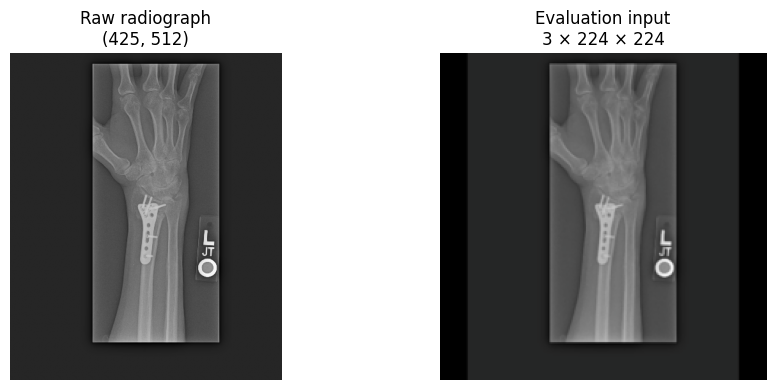

{'study_uid': 'patient00006/study1_positive', 'label_binary': 1, 'tensor_shape': (3, 224, 224)}


In [45]:
# Visual and deterministic-evaluation smoke test. This fits no model.

sample = train_clean.iloc[0]

with zipfile.ZipFile(RAW_ZIP, "r") as archive:
    member = resolve_zip_member(
        sample[PATH_COLUMN],
        set(archive.namelist()),
    )
    raw = Image.open(
        io.BytesIO(archive.read(member))
    ).copy()

tensor_a = evaluation_transform(raw)
tensor_b = evaluation_transform(raw)

assert torch.equal(
    tensor_a,
    tensor_b,
), "Evaluation preprocessing must be deterministic."

assert tuple(tensor_a.shape) == (3, 224, 224), (
    f"Unexpected shape: {tuple(tensor_a.shape)}"
)

assert torch.isfinite(tensor_a).all(), (
    "Found non-finite transformed values."
)

# Undo ImageNet normalization only for visualization.
preview = tensor_a.permute(1, 2, 0).numpy()
preview = np.clip(
    preview * np.asarray(IMAGENET_STD)
    + np.asarray(IMAGENET_MEAN),
    0,
    1,
)

fig, axes = plt.subplots(1, 2, figsize=(10, 4))

axes[0].imshow(raw.convert("L"), cmap="gray")
axes[0].set_title(f"Raw radiograph\n{raw.size}")
axes[0].axis("off")

axes[1].imshow(preview)
axes[1].set_title("Evaluation input\n3 × 224 × 224")
axes[1].axis("off")

plt.tight_layout()
plt.show()

print({
    "study_uid": sample.study_uid,
    "label_binary": int(sample.label_binary),
    "tensor_shape": tuple(tensor_a.shape),
})

## Handoff contract

The next notebook should use only the cleaned internal manifests produced here and must apply this exact deterministic `evaluation_transform` when extracting frozen ResNet-18 features. It must preserve `patient_id`, `study_uid`, and image/view identity, then aggregate views into one study-level prediction.

The official MURA valid split was historically observed in Phase 1 and cannot be used for new model, threshold, calibration, or architecture selection.